# 03 LightGBM vs. MLP at equal budget
Goal: pick the teacher and the student family fairly. This is not a verdict on trees vs. nets. Both models get the same budget from `configs/config.yaml`: `tune.n_trials` trials and `tune.time_cap_seconds` seconds, whichever runs out first. The search code lives in `src/tune.py`.

In [1]:
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split

from src.lib import RESULTS_DIR, evaluate_regression, load_data, load_split
from src.tune import fit_predict_lgbm, fit_predict_mlp
from src.utils import load_config

cfg = load_config()
seed = cfg["seed"]
X, y = load_data()
X, y = X.to_numpy(), y.to_numpy()

# The test rows are used only once, in the Report section at the end.
test_idx, folds = load_split()
dev_idx = np.sort(np.concatenate([val for _, val in folds]))  # the full training portion
print("budget:", cfg["tune"])

budget: {'n_trials': 20, 'time_cap_seconds': 900}


## The searches
Run from the command line, one process per model. LightGBM and PyTorch each bring their own OpenMP runtime and can freeze when they share a process during training.

```
python -m src.tune --model lgbm
python -m src.tune --model mlp
```

Each writes `results/trials_<model>.csv` (one row per trial) and `results/best_<model>.json`. Load them here.

In [2]:
trials = {
    "LightGBM": pd.read_csv(RESULTS_DIR / "trials_lgbm.csv"),
    "MLP": pd.read_csv(RESULTS_DIR / "trials_mlp.csv"),
}
pd.DataFrame(
    {
        name: {
            "trials run": len(d),
            "total seconds": round(d["cumulative_seconds"].iloc[-1]),
            "median seconds per trial": round(d["trial_seconds"].median(), 1),
            "best CV RMSE": round(d["cv_rmse_mean"].min(), 4),
        }
        for name, d in trials.items()
    }
)

,LightGBM,MLP
trials run,20.0000,20.0000
total seconds,555.0000,139.0000
median seconds per trial,23.2000,5.9000
best CV RMSE,0.4492,0.5184


## Budget curves
Best 5-fold CV score so far, against trial number and against cumulative wall-clock seconds. One trial costs very different amounts of time for the two models, so equal trials alone would not be an equal budget.

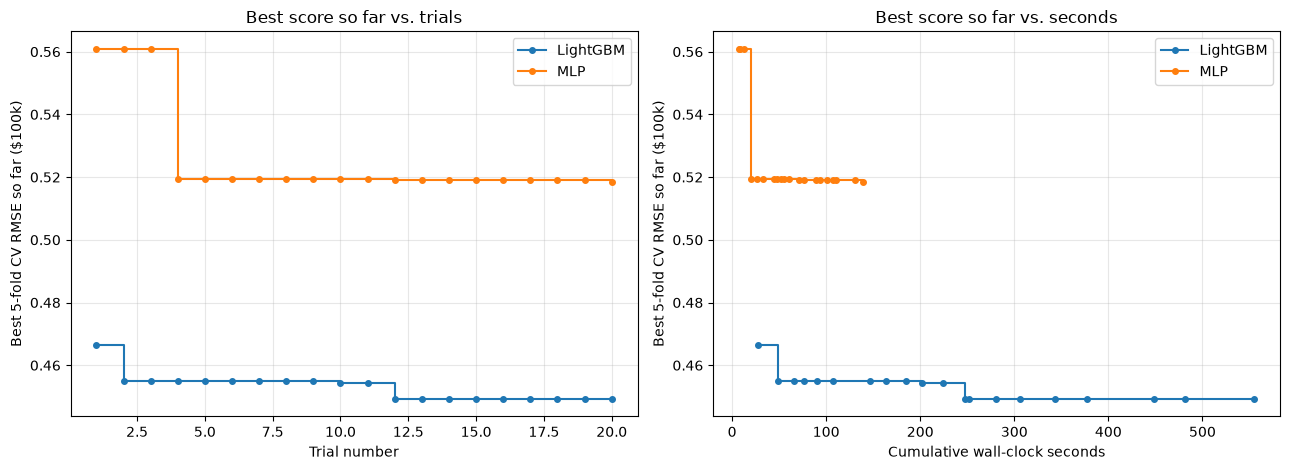

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
for name, d in trials.items():
    best_so_far = d["cv_rmse_mean"].cummin()
    axes[0].step(d["trial"], best_so_far, where="post", marker="o", ms=4, label=name)
    axes[1].step(d["cumulative_seconds"], best_so_far, where="post", marker="o", ms=4, label=name)

axes[0].set_xlabel("Trial number")
axes[0].set_title("Best score so far vs. trials")
axes[1].set_xlabel("Cumulative wall-clock seconds")
axes[1].set_title("Best score so far vs. seconds")
for ax in axes:
    ax.set_ylabel("Best 5-fold CV RMSE so far ($100k)")
    ax.grid(alpha=0.3)
    ax.legend()
fig.tight_layout()
fig.savefig(RESULTS_DIR / "fig3_equal_budget.png", dpi=150)
plt.show()

**Takeaways**
- **LightGBM leads at every point.** Its first trial (0.466, after about 28 s) already beats the MLP's best of 0.518 after all 20 trials.
- **The MLP stalls early.** Its best score is 0.519 from trial 4, and the 16 trials after that improve it by only 0.001.
- **Equal trials were not equal time.** LightGBM used 555 s and the MLP 139 s, and neither came near the 900 s cap, so the cap never decided anything here. Compared by seconds, LightGBM is still ahead: it reaches 0.455 by about 50 s.

## Report
Refit each model's best parameters on the full training portion and score it on the test set, once. Early stopping uses a 10% slice of the training rows, as in the search.

In [4]:
# Same procedure as in the search: early stopping on a 10% slice of the training rows.
fit_idx, stop_idx = train_test_split(dev_idx, test_size=0.1, random_state=seed)

rows = []
# LightGBM first: LightGBM and torch share a process here, so torch must not be loaded before it.
for name, key, fit_predict in [
    ("LightGBM", "lgbm", fit_predict_lgbm),
    ("MLP", "mlp", fit_predict_mlp),
]:
    best = json.loads((RESULTS_DIR / f"best_{key}.json").read_text())
    pred = fit_predict(best["params"], X, y, fit_idx, stop_idx, test_idx, seed)
    d = trials[name]
    rows.append(
        {
            "model": name,
            "trials_run": len(d),
            "trial_limit": cfg["tune"]["n_trials"],
            "seconds_used": round(d["cumulative_seconds"].iloc[-1], 1),
            "time_cap_seconds": cfg["tune"]["time_cap_seconds"],
            "cv_rmse_mean": best["cv_rmse_mean"],
            "cv_rmse_std": best["cv_rmse_std"],
            "test_rmse": evaluate_regression(y[test_idx], pred)["rmse"],
        }
    )

summary = pd.DataFrame(rows).set_index("model")
summary.to_csv(RESULTS_DIR / "tuning_summary.csv")
summary.round(4)

,trials_run,trial_limit,seconds_used,time_cap_seconds,cv_rmse_mean,cv_rmse_std,test_rmse
model,,,,,,,
LightGBM,20,20,555.1,900,0.4492,0.0133,0.4413
MLP,20,20,138.9,900,0.5184,0.0167,0.5300


**Takeaways** (20 trials each, same budget)
- **LightGBM is ahead.** Test RMSE is 0.441 against 0.530 for the MLP, about 17% lower. CV tells the same story: 0.449 ± 0.013 against 0.518 ± 0.017.
- **Tuning did not overfit the folds.** Each test RMSE is within about one fold std of its CV score (LightGBM 0.008 lower, MLP 0.012 higher).
- **This is a result under this budget, not a verdict on trees vs. nets.** It is one dataset, 20 trials, and a 7-setting space for LightGBM against a 5-setting space for the MLP.
- **Choice for the next step:** LightGBM goes into the teacher, and the MLP is the student family.